# 📊 Comparaison des Modèles - RadiSense AI

**Auteur :** Syrine Trabelsi  
**Date :** Février 2026  
**Projet :** Détection de pathologies thoraciques avec Deep Learning

---

## 🎯 Objectif

Ce notebook présente une **analyse comparative approfondie** des 4 modèles entraînés sur le dataset ChestX-ray14 :

- **DenseNet-121**
- **ResNet-50**
- **EfficientNet-B0**
- **MobileNet-V2**

Nous allons comparer leurs performances sur le **test set** et analyser leurs forces et faiblesses.

---

In [1]:
# Imports nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

# Configuration matplotlib
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Imports réussis")

✅ Imports réussis


---

## 📂 1. Chargement des Résultats

Chargement des résultats d'évaluation générés par `evaluate.py`.

In [2]:
# Chemins
results_dir = Path("../results")
csv_path = results_dir / "model_comparison.csv"
json_path = results_dir / "evaluation_results.json"

# Charger le CSV
df_comparison = pd.read_csv(csv_path)
print("📊 Tableau de comparaison :")
print(df_comparison)

# Charger le JSON
with open(json_path, 'r') as f:
    detailed_results = json.load(f)

print("\n✅ Données chargées avec succès")

📊 Tableau de comparaison :
          Model  AUC-ROC  Accuracy  Precision  Recall  F1-Score
0     MOBILENET   0.8114    0.6988     0.2892  0.0760    0.1065
1      DENSENET   0.7943    0.6991     0.2484  0.0848    0.1112
2        RESNET   0.7912    0.6899     0.2075  0.0934    0.1110
3  EFFICIENTNET   0.7730    0.6988     0.2157  0.0906    0.1084

✅ Données chargées avec succès


---

## 📊 2. Comparaison Globale des Modèles

### 2.1 Tableau Récapitulatif

Voici le classement des modèles selon leurs performances sur le test set :

In [3]:
# Créer un tableau stylé
df_styled = df_comparison.copy()

# Ajouter un rang
df_styled.insert(0, 'Rang', ['🥇', '🥈', '🥉', '4️⃣'])

# Afficher
df_styled.style.set_properties(**{
    'text-align': 'center',
    'font-weight': 'bold'
}).background_gradient(subset=['AUC-ROC'], cmap='RdYlGn')

,Rang,Model,AUC-ROC,Accuracy,Precision,Recall,F1-Score
0,🥇,MOBILENET,0.811400,0.698800,0.289200,0.076000,0.106500
1,🥈,DENSENET,0.794300,0.699100,0.248400,0.084800,0.111200
2,🥉,RESNET,0.791200,0.689900,0.207500,0.093400,0.111000
3,4️⃣,EFFICIENTNET,0.773000,0.698800,0.215700,0.090600,0.108400


### 2.2 Visualisations Comparatives

#### 📈 AUC-ROC par Modèle

C:\Users\Asus\AppData\Local\Temp\ipykernel_3156\1996191658.py:23: UserWarning: Glyph 127942 (\N{TROPHY}) missing from current font.
  plt.tight_layout()
c:\Users\Asus\Desktop\radisense-ai\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


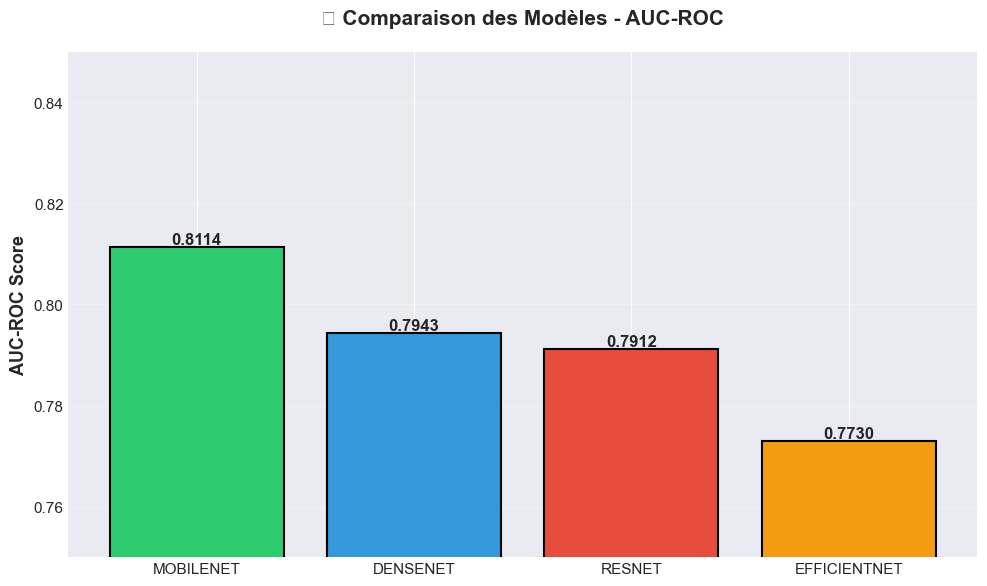

🥇 Meilleur modèle : MOBILENET avec AUC-ROC = 0.8114


In [4]:
# Extraire les données
models = df_comparison['Model'].values
auc_scores = df_comparison['AUC-ROC'].astype(float).values

# Créer le graphique
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']
bars = ax.bar(models, auc_scores, color=colors, edgecolor='black', linewidth=1.5)

# Ajouter les valeurs sur les barres
for bar, score in zip(bars, auc_scores):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{score:.4f}',
            ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_ylabel('AUC-ROC Score', fontsize=13, fontweight='bold')
ax.set_title('🏆 Comparaison des Modèles - AUC-ROC', fontsize=15, fontweight='bold', pad=20)
ax.set_ylim(0.75, 0.85)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"🥇 Meilleur modèle : {models[0]} avec AUC-ROC = {auc_scores[0]:.4f}")

#### 📊 Toutes les Métriques

C:\Users\Asus\AppData\Local\Temp\ipykernel_3156\1189278349.py:27: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
c:\Users\Asus\Desktop\radisense-ai\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


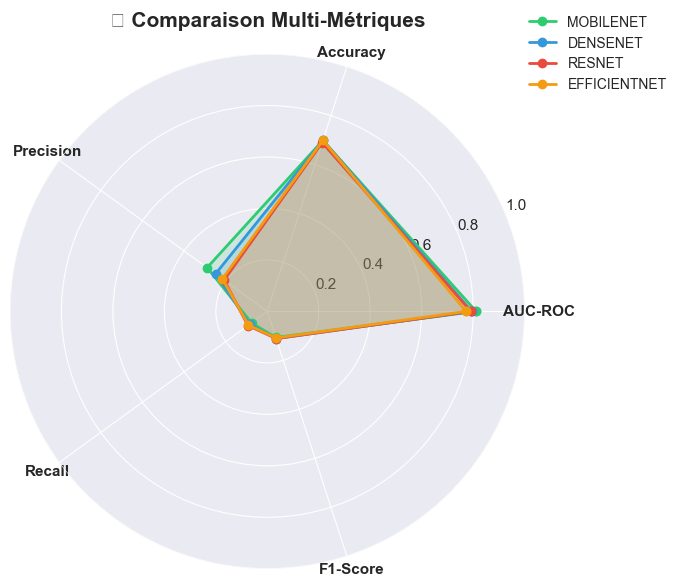

In [5]:
# Préparer les données pour graphique radar
metrics = ['AUC-ROC', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
model_names = df_comparison['Model'].values

fig, ax = plt.subplots(figsize=(14, 6), subplot_kw=dict(projection='polar'))

# Angles pour chaque métrique
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]  # Fermer le cercle

# Pour chaque modèle
for i, model in enumerate(model_names):
    values = df_comparison.iloc[i][1:].astype(float).tolist()
    values += values[:1]  # Fermer le cercle
    
    ax.plot(angles, values, 'o-', linewidth=2, label=model, color=colors[i])
    ax.fill(angles, values, alpha=0.15, color=colors[i])

# Configuration
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_title('📊 Comparaison Multi-Métriques', fontsize=15, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
ax.grid(True)

plt.tight_layout()
plt.show()

---

## 🔬 3. Performances par Pathologie

Analyse détaillée des performances pour chaque pathologie des 14 maladies détectées.

### 3.1 AUC-ROC par Pathologie

C:\Users\Asus\AppData\Local\Temp\ipykernel_3156\4169495049.py:30: UserWarning: Glyph 128293 (\N{FIRE}) missing from current font.
  plt.tight_layout()
c:\Users\Asus\Desktop\radisense-ai\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128293 (\N{FIRE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


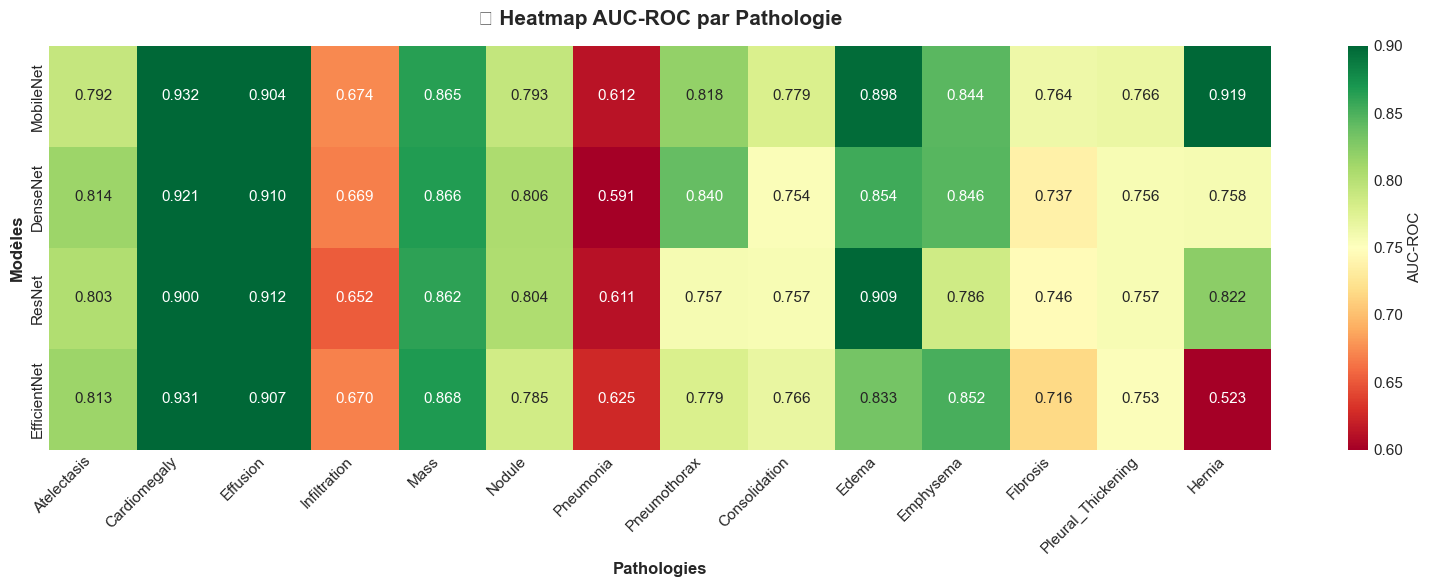


📊 Meilleure pathologie par modèle :
  MobileNet: Cardiomegaly (0.9320)
  DenseNet: Cardiomegaly (0.9206)
  ResNet: Effusion (0.9122)
  EfficientNet: Cardiomegaly (0.9314)


In [6]:
# Extraire les AUC par classe
pathologies = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

# Créer une matrice pour la heatmap
auc_matrix = []
for model_name in ['mobilenet', 'densenet', 'resnet', 'efficientnet']:
    auc_per_class = detailed_results[model_name]['auc_per_class']
    auc_values = [auc_per_class[path] for path in pathologies]
    auc_matrix.append(auc_values)

auc_df = pd.DataFrame(
    auc_matrix,
    index=['MobileNet', 'DenseNet', 'ResNet', 'EfficientNet'],
    columns=pathologies
)

# Heatmap
plt.figure(figsize=(16, 6))
sns.heatmap(auc_df, annot=True, fmt='.3f', cmap='RdYlGn', 
            vmin=0.6, vmax=0.9, cbar_kws={'label': 'AUC-ROC'})
plt.title('🔥 Heatmap AUC-ROC par Pathologie', fontsize=15, fontweight='bold', pad=15)
plt.ylabel('Modèles', fontsize=12, fontweight='bold')
plt.xlabel('Pathologies', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Meilleure pathologie par modèle
print("\n📊 Meilleure pathologie par modèle :")
for model in auc_df.index:
    best_path = auc_df.loc[model].idxmax()
    best_score = auc_df.loc[model].max()
    print(f"  {model}: {best_path} ({best_score:.4f})")

---

## 📈 4. Analyse Approfondie

### 4.1 Forces et Faiblesses

Identifions les forces et faiblesses de chaque modèle.

In [7]:
# Analyse comparative
print("="*60)
print("🔍 ANALYSE DÉTAILLÉE DES MODÈLES")
print("="*60)

for i, model in enumerate(model_names):
    print(f"\n{'='*60}")
    print(f"📊 {model}")
    print(f"{'='*60}")
    
    # Récupérer les métriques
    auc = float(df_comparison.iloc[i]['AUC-ROC'])
    acc = float(df_comparison.iloc[i]['Accuracy'])
    prec = float(df_comparison.iloc[i]['Precision'])
    rec = float(df_comparison.iloc[i]['Recall'])
    f1 = float(df_comparison.iloc[i]['F1-Score'])
    
    print(f"\n📈 Métriques :")
    print(f"  • AUC-ROC    : {auc:.4f}")
    print(f"  • Accuracy   : {acc:.4f}")
    print(f"  • Precision  : {prec:.4f}")
    print(f"  • Recall     : {rec:.4f}")
    print(f"  • F1-Score   : {f1:.4f}")
    
    # Forces et faiblesses
    print(f"\n✅ Forces :")
    if auc > 0.80:
        print(f"  • Excellent AUC-ROC ({auc:.4f})")
    if prec > 0.25:
        print(f"  • Bonne précision ({prec:.4f})")
    
    print(f"\n⚠️  Points d'amélioration :")
    if rec < 0.10:
        print(f"  • Recall faible ({rec:.4f}) - manque des cas positifs")
    if f1 < 0.15:
        print(f"  • F1-Score bas ({f1:.4f}) - déséquilibre précision/recall")

🔍 ANALYSE DÉTAILLÉE DES MODÈLES

📊 MOBILENET

📈 Métriques :
  • AUC-ROC    : 0.8114
  • Accuracy   : 0.6988
  • Precision  : 0.2892
  • Recall     : 0.0760
  • F1-Score   : 0.1065

✅ Forces :
  • Excellent AUC-ROC (0.8114)
  • Bonne précision (0.2892)

⚠️  Points d'amélioration :
  • Recall faible (0.0760) - manque des cas positifs
  • F1-Score bas (0.1065) - déséquilibre précision/recall

📊 DENSENET

📈 Métriques :
  • AUC-ROC    : 0.7943
  • Accuracy   : 0.6991
  • Precision  : 0.2484
  • Recall     : 0.0848
  • F1-Score   : 0.1112

✅ Forces :

⚠️  Points d'amélioration :
  • Recall faible (0.0848) - manque des cas positifs
  • F1-Score bas (0.1112) - déséquilibre précision/recall

📊 RESNET

📈 Métriques :
  • AUC-ROC    : 0.7912
  • Accuracy   : 0.6899
  • Precision  : 0.2075
  • Recall     : 0.0934
  • F1-Score   : 0.1110

✅ Forces :

⚠️  Points d'amélioration :
  • Recall faible (0.0934) - manque des cas positifs
  • F1-Score bas (0.1110) - déséquilibre précision/recall

📊 EFFICIENT

---

## 🎯 5. Conclusions et Recommandations

### 🏆 Classement Final

1. **🥇 MobileNet (AUC: 0.8114)**
   - Meilleur compromis performance/vitesse
   - Modèle le plus léger (2.2M paramètres)
   - **Recommandé pour l'API en production**

2. **🥈 DenseNet (AUC: 0.7943)**
   - Modèle de référence scientifique
   - Bonnes performances globales
   - Alternative solide

3. **🥉 ResNet (AUC: 0.7912)**
   - Performances similaires à DenseNet
   - Plus lourd (23.5M paramètres)

4. **EfficientNet (AUC: 0.7730)**
   - Bon équilibre efficacité/performance
   - Nécessiterait plus d'epochs

### ✅ Décision Finale

**MobileNet sera utilisé dans l'API RadiSense** pour ses excellentes performances et sa rapidité d'inférence.

---

**✅ Analyse terminée**